# Pure-axis isolation — figure

Figure for `sec:depth-vs-experts` in `docs/latex/main.tex`: full-suite HumanEval-TS
pass@1 vs. approximate parameter count, one line for the pure experts-only
candidates (`depth_n=0`) and one for the pure depth-only candidates
(`expert_n=0`), against the reconciled baseline. Loads the already-committed
`docs/debug/phase4_pure_axis_*` and `docs/debug/phase4_depth0_experts60_*`
run summaries plus `docs/debug/phase4_baseline_humaneval_ts_full159_*` — no GPU
needed, this just plots results already measured and archived elsewhere.


In [1]:
import json
from pathlib import Path

DEBUG = Path("../docs/debug")

# (label, prefix, approx params in B) -- params from the project's per-layer
# param formula (plan.md), same values already in the pure-axis table in
# docs/latex/main.tex.
EXPERTS_ONLY = [
    ("experts112", "phase4_pure_axis_depth0_experts112_fixedloss_short", 5.15),
    ("experts64", "phase4_pure_axis_depth0_experts64_fixedloss_short", 16.03),
    ("experts60", "phase4_depth0_experts60_fixedloss_short", 16.94),
    ("experts32", "phase4_pure_axis_depth0_experts32_fixedloss_short", 23.28),
    ("experts16", "phase4_pure_axis_depth0_experts16_fixedloss_short", 26.91),
    ("experts8", "phase4_pure_axis_depth0_experts8_fixedloss_short", 28.72),
]
DEPTH_ONLY = [
    ("depth24", "phase4_pure_axis_depth24_experts0_fixedloss_short", 15.58),
    ("depth16", "phase4_pure_axis_depth16_experts0_fixedloss_short", 20.56),
]


def load_full_pass_at_1(prefix: str) -> float:
    metrics = json.loads((DEBUG / f"{prefix}_humaneval_ts_full.json").read_text())
    assert metrics["config"]["limit"] is None, prefix
    return metrics["multiple-ts"]["pass@1"]


experts_params = [p for _, _, p in EXPERTS_ONLY]
experts_pass = [load_full_pass_at_1(prefix) for _, prefix, _ in EXPERTS_ONLY]
depth_params = [p for _, _, p in DEPTH_ONLY]
depth_pass = [load_full_pass_at_1(prefix) for _, prefix, _ in DEPTH_ONLY]

baseline_metrics = json.loads(
    (DEBUG / "phase4_baseline_humaneval_ts_full159_humaneval_ts_full.json").read_text()
)
assert baseline_metrics["config"]["limit"] is None
baseline_pass = baseline_metrics["multiple-ts"]["pass@1"]

{
    "experts_only": list(zip(experts_params, experts_pass, strict=True)),
    "depth_only": list(zip(depth_params, depth_pass, strict=True)),
    "baseline": baseline_pass,
}

{'experts_only': [(5.15, 0.08176100628930817),
  (16.03, 0.5786163522012578),
  (16.94, 0.5723270440251572),
  (23.28, 0.6037735849056604),
  (26.91, 0.6477987421383647),
  (28.72, 0.7044025157232704)],
 'depth_only': [(15.58, 0.1069182389937107), (20.56, 0.2830188679245283)],
 'baseline': 0.7169811320754716}

## The figure

Experts-only (six points, sorted by parameters) and depth-only (two points)
against the reconciled 159-problem baseline, dashed. Every experts-only point
from experts8 through experts64 tracks close to baseline; experts112 collapses.
Both depth-only points sit far below baseline despite comparable or larger
parameter counts than several experts-only points.


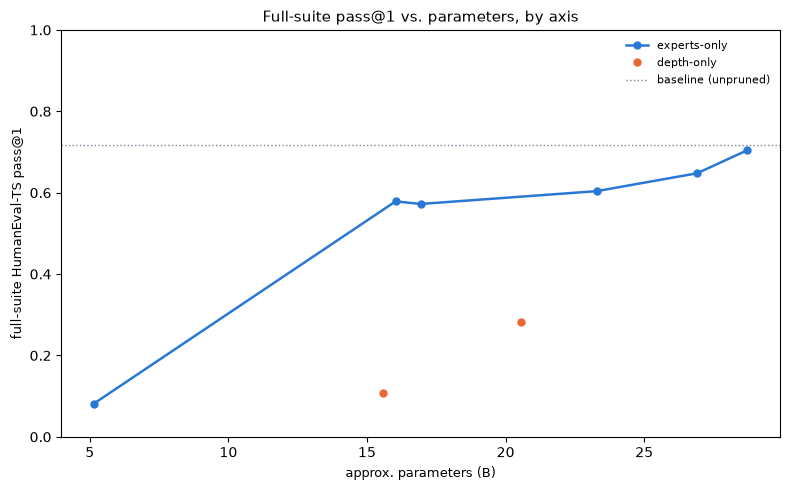

In [2]:
from bonsai.pruning.viz import plot_axis_isolation

# Sort each series by parameters ascending so the connecting line reads left-to-right.
experts_sorted = sorted(zip(experts_params, experts_pass, strict=True))
depth_sorted = sorted(zip(depth_params, depth_pass, strict=True))

series = {
    "experts-only": tuple(zip(*experts_sorted, strict=True)),
    "depth-only": tuple(zip(*depth_sorted, strict=True)),
}

fig = plot_axis_isolation(series, baseline_pass_at_1=baseline_pass)
fig.savefig("../docs/latex/figures/pure_axis_isolation.png", dpi=150)
fig.savefig("../docs/latex/figures/pure_axis_isolation.pdf")